# lora_arm — generate the 488-row test set with a trained adapter
Minimal edit of `prompting_arm`: the pipeline build grafts the converted adapter with `transformer.load_lora_adapter`, and the config points at one rank's checkpoint. `inference.py` uses `pipeline.load_lora_weights`, which fails against current diffusers — OmniGen2's `lora_state_dict` iterates the return value of `_fetch_state_dict`, now a `(state_dict, metadata)` tuple. Sampler, resolution, negative prompt, seed, and the resumable engine are unchanged, so output is comparable to the scored baseline. Set `RANK` to 4, 8, or 16 and run; resumable via `GEN`. No new levers — the only change from baseline is the adapter.

## 1. Repo

In [ ]:
import os, subprocess, sys
REPO = "/content/OmniGen2"
if not os.path.isdir(REPO):
    subprocess.run(["git","clone","https://github.com/VectorSpaceLab/OmniGen2.git",REPO], check=True)
    subprocess.run([sys.executable,"-m","pip","install","-q","-r","requirements.txt"], cwd=REPO, check=True)
    subprocess.run([sys.executable,"-m","pip","install","-q","-U","huggingface_hub[hf_xet]>=0.30.0,<1.0"], check=True)
    print("installed.")
else:
    print("OmniGen2 already present.")

# peft's LoRA injection walks dispatch_torchao, which raises rather than returning False when torchao
# predates 0.16 (Colab ships 0.10). torchao is unused by this bf16 path; removing it lets injection
# proceed. Same fix the converter and training notebooks use. Guarded, so it is a no-op once gone.
_ao = subprocess.run([sys.executable, "-c",
                      "from peft.import_utils import is_torchao_available; is_torchao_available()"],
                     capture_output=True, text=True)
if _ao.returncode != 0:
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], check=True)
    print("torchao removed")

sys.path.insert(0, REPO)
os.chdir(REPO)

OmniGen2 already present.


## 2. Drive, run config, adapter path

In [ ]:
from google.colab import drive, userdata
import os
drive.mount("/content/drive")
os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")

DRIVE   = "/content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data"
DATASET = "test"          # the 488-row held-out evaluation set
RANK    = 16              # 4 | 8 | 16 — the adapter under test
STEP    = 4000
RUN     = f"lora_r{RANK}"

EXP      = f"{DRIVE}/lora/experiments"
LORA_DIR = f"{EXP}/{RUN}/checkpoint-{STEP}/transformer_lora"
LORA     = f"{LORA_DIR}/pytorch_lora_weights.safetensors"
assert os.path.exists(LORA), f"adapter missing, run lora_convert first: {LORA}"

GEN = f"{DRIVE}/gen/{DATASET}/{RUN}"
os.makedirs(GEN, exist_ok=True)
n_have = len([f for f in os.listdir(GEN) if f.endswith(".png")])
print(f"data    : {DRIVE}")
print(f"adapter : {LORA}")
print(f"output  : {GEN}")
print(f"already generated: {n_have}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
data    : /content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data
adapter : /content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data/lora/experiments/lora_r16/checkpoint-4000/transformer_lora/pytorch_lora_weights.safetensors
output  : /content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data/gen/test/lora_r16
already generated: 0


## 3. Images, split files

In [ ]:
import subprocess, json
IMGS, EXPECTED = "/content/imgs", 37063
TAR = f"{DRIVE}/imgs_subset.tar"
def n_files(d): return sum(len(f) for _,_,f in os.walk(d)) if os.path.isdir(d) else 0
if n_files(IMGS) < EXPECTED:
    os.makedirs(IMGS, exist_ok=True)
    subprocess.run(f'cp "{TAR}" /content/imgs_subset.tar && tar -xf /content/imgs_subset.tar -C {IMGS}', shell=True, check=True)
    print("restored", n_files(IMGS), "/", EXPECTED)
    assert n_files(IMGS) >= EXPECTED, "restore incomplete"
else:
    print("images complete:", n_files(IMGS))

for s in ["train","val","test","screen","screen_small"]:
    src = f"{DRIVE}/{s}.jsonl"
    if os.path.exists(src) and not os.path.exists(f"/content/{s}.jsonl"):
        subprocess.run(["cp", src, f"/content/{s}.jsonl"])

rows = [json.loads(l) for l in open(f"/content/{DATASET}.jsonl", encoding="utf-8")]
missing = [p for r in rows for p in r["input_images"] if not os.path.exists(os.path.join(IMGS, p))]
assert not missing, f"{len(missing)} reference images missing, first: {missing[:3]}"
print(f"{DATASET}: {len(rows)} rows, all reference images present")

images complete: 37063
test: 488 rows, all reference images present


## 4. Model and adapter

In [ ]:
import torch
from accelerate import Accelerator
from omnigen2.pipelines.omnigen2.pipeline_omnigen2 import OmniGen2Pipeline
from omnigen2.models.transformers.transformer_omnigen2 import OmniGen2Transformer2DModel

MODEL = "OmniGen2/OmniGen2"
accelerator = Accelerator(mixed_precision="bf16")
dtype = torch.bfloat16

# same construction as inference.py load_pipeline (base pipeline, base transformer), except that
# the adapter is grafted with transformer.load_lora_adapter: inference.py's pipeline.load_lora_weights
# fails against current diffusers, since OmniGen2's lora_state_dict iterates the return value of
# _fetch_state_dict, now a (state_dict, metadata) tuple
pipe = OmniGen2Pipeline.from_pretrained(MODEL, torch_dtype=dtype, trust_remote_code=True)
pipe.transformer = OmniGen2Transformer2DModel.from_pretrained(MODEL, subfolder="transformer", torch_dtype=dtype)
pipe.transformer.load_lora_adapter(LORA_DIR, weight_name="pytorch_lora_weights.safetensors", prefix="transformer")
pipe = pipe.to(accelerator.device)
print(f"pipeline ready on {accelerator.device} with adapter r{RANK} loaded")

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Expected types for transformer: (<class 'omnigen2.models.transformers.transformer_omnigen2.OmniGen2Transformer2DModel'>,), got <class 'diffusers_modules.local.transformer_omnigen2.OmniGen2Transformer2DModel'>.


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

pipeline ready on cuda with adapter r16 loaded


## 5. Engine and run config

In [ ]:
from PIL import Image, ImageOps
import torch

# shipped default from inference.py and omnicontext/inference.py; quality filter, not a domain negative
NEG = ("(((deformed))), blurry, over saturation, bad anatomy, disfigured, poorly drawn face, mutation, mutated, "
       "(extra_limb), (ugly), (poorly drawn hands), fused fingers, messy drawing, broken legs censor, censored, censor_bar")

def load_inputs(paths, max_side=512):   # refs downscaled; output size fixed at 512 via align_res=False
    out = []
    for p in paths:
        im = ImageOps.exif_transpose(Image.open(p).convert("RGB"))
        w, h = im.size
        s = max_side / max(w, h)
        if s < 1: w, h = int(w*s), int(h*s)
        w, h = max(16, (w//16)*16), max(16, (h//16)*16)
        out.append(im.resize((w, h), Image.LANCZOS))
    return out

def generate(instruction, input_images=None, negative=NEG, seed=0, steps=50, text_g=5.0, image_g=2.0, size=512):
    gen = torch.Generator(device=accelerator.device).manual_seed(seed)
    res = pipe(prompt=instruction, input_images=input_images,
               width=size, height=size, num_inference_steps=steps, max_sequence_length=1024,
               text_guidance_scale=text_g, image_guidance_scale=image_g, cfg_range=(0.0, 1.0),
               negative_prompt=negative, num_images_per_prompt=1, generator=gen, output_type="pil",
               align_res=False)
    return res.images[0]

# no prompt lever in this arm: the adapter is the treatment, instruction and negative are the baseline
cfg = dict(instruction=lambda r: r["instruction"], negative=NEG)
_probe = {"instruction": "<probe>", "input_images": []}
print(f"run '{RUN}'")
print(f"  instruction : {'unchanged' if cfg['instruction'](_probe) == '<probe>' else 'transformed'}")
print(f"  negative    : {'shipped default' if cfg['negative'] == NEG else 'custom'}")
print(f"  sampler     : 50 steps, text_g=5.0, image_g=2.0, cfg_range=(0,1), seed 0, 512x512  (fixed across all conditions)")

run 'lora_r16'
  instruction : unchanged
  negative    : shipped default
  sampler     : 50 steps, text_g=5.0, image_g=2.0, cfg_range=(0,1), seed 0, 512x512  (fixed across all conditions)


## 6. Smoke — 3 rows

  0%|          | 0/50 [00:00<?, ?it/s]

row 0: 1 ref(s), output (512, 512), 31.2s


  0%|          | 0/50 [00:00<?, ?it/s]

row 1: 1 ref(s), output (512, 512), 22.4s


  0%|          | 0/50 [00:00<?, ?it/s]

row 2: 1 ref(s), output (512, 512), 21.9s


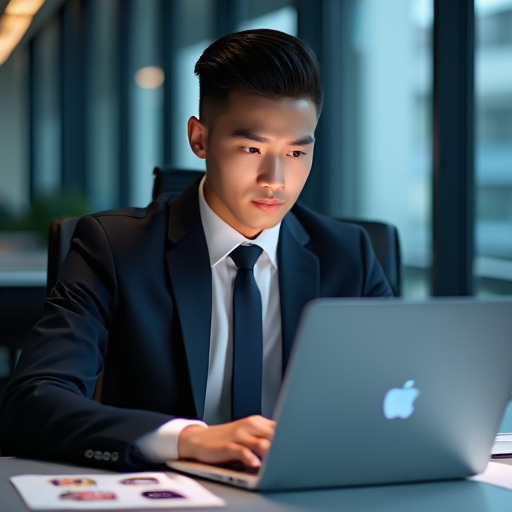

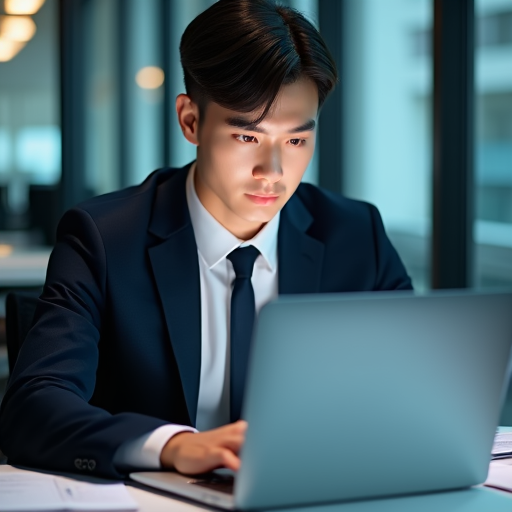

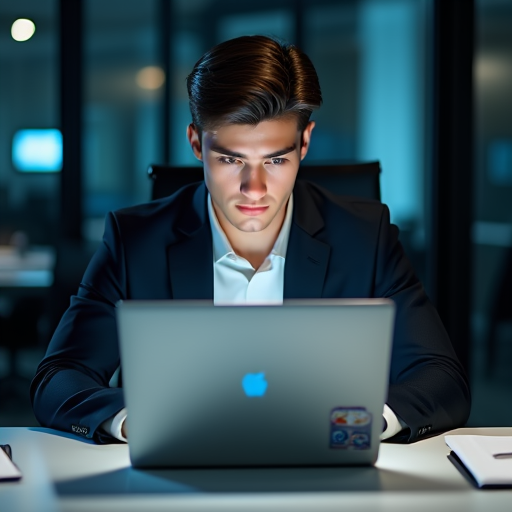

In [ ]:
import time
for i in range(3):
    r = rows[i]
    refs = load_inputs([os.path.join(IMGS, p) for p in r["input_images"]])
    t = time.time()
    img = generate(cfg["instruction"](r), input_images=refs, negative=cfg["negative"], seed=0)
    print(f"row {i}: {len(refs)} ref(s), output {img.size}, {time.time()-t:.1f}s")
    assert img.size == (512, 512), f"expected 512x512, got {img.size}"
    img.save(f"/content/smoke_{i}.png")

from IPython.display import display
for i in range(3):
    display(Image.open(f"/content/smoke_{i}.png"))

## 7. Full pass (resumable)

In [ ]:
import time
done, t0 = 0, time.time()
for i, r in enumerate(rows):
    out = f"{GEN}/{i:05d}.png"
    if os.path.exists(out):
        continue
    refs = load_inputs([os.path.join(IMGS, p) for p in r["input_images"]])
    img = generate(cfg["instruction"](r), input_images=refs, negative=cfg["negative"], seed=0)
    assert img.size == (512, 512), (i, img.size)
    img.save(out)
    done += 1
    if done % 10 == 0:
        print(f"generated {done} (at row {i+1}/{len(rows)}), {(time.time()-t0)/done:.1f}s/img")

total = len([f for f in os.listdir(GEN) if f.endswith(".png")])
print(f"\n{DATASET}/{RUN}: {total}/{len(rows)} images in {GEN}")
assert total == len(rows), "incomplete"

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

...

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]


test/lora_r16: 488/488 images in /content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data/gen/test/lora_r16


## 8. Manifest

In [ ]:
# manifest: provenance for the images in GEN. Written only when this session generated some,
# so a skip-through or resumed run cannot stamp the wrong GPU onto images made earlier.
if not done:
    print(f"no images generated this session; {GEN}/manifest.json left as-is")
else:
    import json, time, subprocess, torch
    man = {
        "dataset": DATASET, "run": RUN,
        "n_images": len([f for f in os.listdir(GEN) if f.endswith(".png")]),
        "gpu": torch.cuda.get_device_name(0),
        "driver": subprocess.run("nvidia-smi --query-gpu=driver_version --format=csv,noheader",
                                 shell=True, capture_output=True, text=True).stdout.strip(),
        "torch": torch.__version__, "cuda": torch.version.cuda, "model": MODEL,
        "sampler": dict(steps=50, text_guidance_scale=5.0, image_guidance_scale=2.0,
                        cfg_range=[0.0, 1.0], max_sequence_length=1024, seed=0,
                        size=512, align_res=False),
        "negative_prompt": cfg["negative"],
        "instruction_row0": cfg["instruction"](rows[0]),
        "bit_reproducible": False,
        "written": time.strftime("%Y-%m-%d %H:%M:%S"),
    }
    with open(f"{GEN}/manifest.json", "w") as f:
        json.dump(man, f, indent=2)
    print("manifest written:", f"{GEN}/manifest.json")

manifest written: /content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data/gen/test/lora_r16/manifest.json
